# Regresión con Procesos Gaussianos: CO₂ de Mauna Loa

Objetivo: ajustar un GP a la serie anual de CO₂, visualizar la posterior (media, ±2σ y muestras) y observar la extrapolación.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
import statsmodels.api as sm

## 1. Datos

- Cargar el dataset `co2` de `statsmodels` (serie semanal).
- Eliminar los valores faltantes.
- Agregar a **media anual**.
- Construir `X_train` (años, forma `(n, 1)`) e `y_train`.

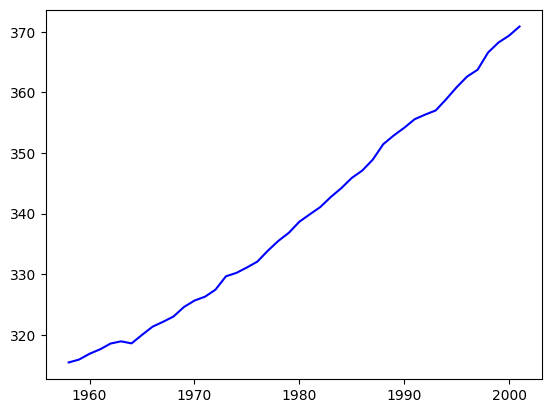

In [20]:
# TODO: cargar y limpiar los datos
df = sm.datasets.co2.load_pandas().data.dropna()
yearly_co2 = df.groupby(df.index.year).mean()
yearly_co2.head()

X_train = yearly_co2.index.to_numpy().reshape(-1,1)
y_train = yearly_co2.co2.to_numpy()

plt.plot(X_train, y_train, color = "blue")
# TODO: media anual

# TODO: X_train, y_train


## 2. Modelo

- Kernel: amplitud × RBF + ruido blanco.
- `GaussianProcessRegressor` con `normalize_y=True` y reinicios del optimizador.
- Ajustar e imprimir los hiperparámetros aprendidos.

In [21]:
# TODO: definir el kernel
kernel = RBF() + WhiteKernel()
# TODO: definir el GP
gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=0).fit(X_train, y_train)

# TODO: ajustar y mostrar gp.kernel_

## 3. Posterior y extrapolación

- Malla `X_test` que se extienda más allá de los datos.
- Media y desviación típica posteriores.
- Muestras de la posterior.

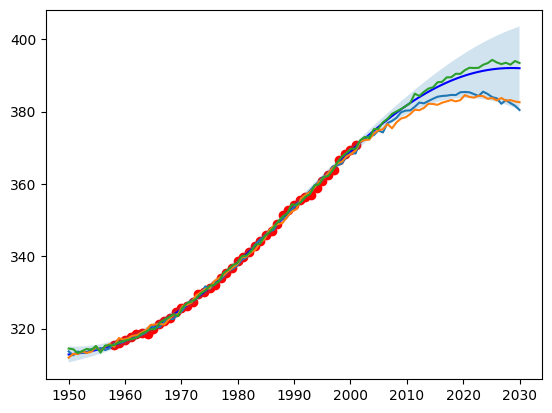

In [34]:
# TODO: X_test
X_test = np.linspace(1950, 2030, num=100).reshape(-1,1)

# TODO: mu_post, std_post
mu_post, std_post =  gp.predict(X_test, return_std=True)
x_samples = gp.sample_y(X_test, n_samples=3)

plt.scatter(X_train, y_train, color="red")
plt.plot(X_test, mu_post, color= "blue")
plt.fill_between(X_test.ravel(), mu_post-2*std_post,mu_post + 2*std_post, alpha= 0.2)
# TODO: muestras f_post
plt.plot(X_test, x_samples)

plt.show()


## 4. Visualización

Dos paneles: vista completa y zoom en una región de interés.
Cada panel: banda ±2σ, muestras, media y datos de entrenamiento.

In [ ]:
# TODO: función auxiliar de dibujo

# TODO: figura con 2 paneles (completo + zoom)


## 5. Discusión

- ¿Qué ocurre con la media y la incertidumbre al extrapolar?
- ¿Qué indica el `length_scale` aprendido?
- ¿Qué estructura de la serie no captura este kernel?